## Imports & Initialization:

In [97]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.evaluation.models.choose_models import KnowledgeMazeRunner
from knowledge_maze.evaluation.utils.preprocess import KnowledgeMazeDatasetDistiller
from knowledge_maze.evaluation.models.model_inference import KnowledgeMazeIncrementalRunner
from knowledge_maze.evaluation.models.judge_model import KnowledgeMazeIncrementalJudge

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
hedged_question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_hedged.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Preliminary Reliability Assessment

Before conducting the full-scale evaluation of **CLECK**, we perform a preliminary reliability check on each model to ensure it possesses the baseline reasoning capabilities required for the benchmark.

### Methodology

* **Stratified Sampling:** We evaluate each model on a subset of **550 random samples**, stratified across our eleven reasoning operations to prevent logical type bias.
* **Reasoning Verification:** To ensure the model can handle the underlying logic of the task, we execute **three Self-Consistency (SC) rounds** for each reasoning paragraph in isolation.
* **Success Criteria:** A model is considered reliable if it achieves an **overall success rate above 90%** across all test cases.
* **General Success Metric:** Additionally, the model must maintain a **general success rate above 90%**, defined as succeeding in at least **2 out of 3 SC rounds** for any given sample.
* **Validation Goal:** This process confirms that the model’s later failures are due to the **latent conflict** rather than a fundamental inability to perform the multi-hop reasoning or the specific mathematical operations, such as counting or filtering.

---

### The "Diagnostic" Logic

By validating reasoning on isolated hops first, we establish a **capability baseline**. This allows us to argue that when a model defaults to an authoritative claim in the full benchmark, it is a behavioral "lock" rather than a lack of logical skill.

In [143]:
runner = KnowledgeMazeRunner(limit=550)
results_df = await runner.execute(question_data, paragraphs)

Model Architecture,Mean Success,General (≥2/3),Strict (3/3),Stability Profile (3 to 0)
deepseek/deepseek-v4-pro,95.2%,97.6%,88.2%,485 52 11 2
mistralai/mistral-medium-3.1,94.4%,94.5%,92.0%,506 14 12 18
meta-llama/llama-4-maverick,94.1%,95.1%,90.4%,497 26 10 17
deepseek/deepseek-v4-flash,94.1%,96.4%,87.6%,482 48 11 9
google/gemini-3-flash-preview,94.1%,94.7%,91.3%,502 19 8 21
openai/gpt-5.4,93.3%,93.5%,91.1%,501 13 10 26
openai/gpt-5.4-mini,92.9%,93.3%,88.5%,487 26 20 17


# Preprocessing Dataset:

### 1. Stratified Population Sampling

To ensure a balanced benchmark, the distiller samples the dataset based on specific research constraints:

* **Hedged Priority**: Automatically includes all **803 Hedged samples** to ensure the uncertainty study is fully represented.
* **Strategy Balancing**: Targets **300 samples per reasoning strategy** (e.g., Temporal Ordering, Multi-hop) for the Full Study.
* **Strict Subsetting**: The **CoT (1.1k)** and **Hedged (803)** datasets are generated as strict subsets of the **Full Study (3.2k)**, allowing for direct paired-sample comparisons.

### 2. Deterministic Context Shuffling

Instead of shuffling paragraphs during the live experiment, the distiller pre-calculates and saves **5 frozen iterations** for every sample:

* **Context IDs**: Each iteration stores a specific list of 10 IDs (1 Evidence, 1 Claim, 8 Distractors) in a fixed sequence.
* **Consistency**: Every model (Gemini, GPT-5, etc.) will see the exact same 5 layouts for Question $X$, ensuring that any performance difference is due to the model architecture, not a "lucky" or "unlucky" shuffle.

### 3. Positional Bias Guardrails

The process includes an automated audit to verify that the shuffling is mathematically "fair":

* **Primacy vs. Recency**: Checks that the Claim does not appear before the Evidence more often than chance (aiming for a ~50/50 split).
* **Edge Salience**: Ensures that both the Truth (Evidence) and the Lie (Claim) occupy high-attention "edge" positions (start/end of context) with equal frequency.

In [141]:
distiller = KnowledgeMazeDatasetDistiller(question_data, paragraphs)
distiller.create_subsets()


════════════════════════════════════════════════════════════
🚀 PREPROCESSING DASHBOARD SUMMARY
════════════════════════════════════════════════════════════
Dataset Name         | Total Samples   |
------------------------------------------------------------
full_study.json      | 2669            |
cot_subset.json      | 1100            |
scaling_subset.json  | 550             |
hedged_subset.json   | 801             |
════════════════════════════════════════════════════════════

### Strategy Distribution Report

| Selected Strategy              | Full           | CoT            | Scaling        | Hedged         |
| ------------------------------ | -------------- | -------------- | -------------- | -------------- |
| AGGREGATION                    | 169 (6.3%)     | 100 (9.1%)     | 50 (9.1%)      | 16 (2.0%)      |
| CATEGORICAL_FILTER_LOOKUP      | 250 (9.4%)     | 100 (9.1%)     | 50 (9.1%)      | 63 (7.9%)      |
| COMPARATIVE_DIFFERENCE         | 250 (9.4%)     | 100 (9.1%)     | 

# Central Execution Logic - Model Evaluation

The framework isolates model behavior by running four distinct experimental iterations using a centralized configuration file. The structure ensures strict control variables by standardizing the output schema (`Explanation` + `Answer`) across all runs, separating reasoning capacity from vocabulary limits.

---

### 1. 📊 Baseline Run ($n=2,600$)
* **Core Objective:** Establish the standard performance floor for the 5 selected Flash/Open models under a uniform, unguided scenario.
* **Prompt Gating:** Uses `BASELINE_PROMPT` (forces an explanation block, but provides zero explicit reasoning steps).
* **Data Context:** Standard, unhedged source paragraphs (`full_study.json`).

### 2. 🧠 Chain-of-Thought (CoT) Ablation ($n=1,100$)
* **Core Objective:** Measure how explicit, step-by-step reasoning guidance shifts conflict awareness and final source preference.
* **Prompt Gating:** Uses `COT_PROMPT` (explicitly forces the model to catalog all relevant text pieces and reason through them sequentially before answering).
* **Data Context:** Core subset evaluation (`cot_subset.json`).

### 3. 📈 Scaling Analysis ($n=660$)
* **Core Objective:** Evaluate whether conflict awareness is an emergent property of model parameter scale by matching a distilled "mini/flash" tier directly against its flagship equivalent.
* **Prompt Gating:** Uses `BASELINE_PROMPT` to isolate raw scaling capacity from engineered prompt guidance.
* **Data Context:** Focused tier comparison subset (`scaling_subset.json`) evaluating `gpt-5-mini` vs. `gpt-5`, and `deepseek-v4-flash` vs. `deepseek-v4-pro`.

### 4. 🌫️ Hedged Context Ablation ($n=800$)
* **Core Objective:** Assess how a model handles explicit, linguistic uncertainty (hedging terms like *“allegedly,” “potentially,”* or *“some sources claim”*) embedded directly within the evidence.
* **Prompt Gating:** Uses `BASELINE_PROMPT` to evaluate if raw linguistic uncertainty forces spontaneous conflict awareness.
* **Data Context:** The runner automatically activates the `use_hedged_text = True` logic, swapping standard target paragraphs for their uncertainty-modified variants (`hedged_subset.json`).

### Run Baseline Inference:

In [541]:
baseline_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="baseline")
await baseline_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: BASELINE
--- Found 269 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/1345 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: mistralai/mistral-medium-3.1 | Mode: BASELINE
--- Found 270 pending samples. Generating frozen prompts...


Inference: mistralai/mistral-medium-3.1:   0%|          | 0/1350 [00:00<?, ?it/s]

>>> Completed run for mistralai/mistral-medium-3.1.

>>> Model: meta-llama/llama-4-maverick | Mode: BASELINE
--- Found 280 pending samples. Generating frozen prompts...


...

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: BASELINE
--- Found 378 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/1890 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.

>>> Model: openai/gpt-5.4-mini | Mode: BASELINE
--- Found 559 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4-mini:   0%|          | 0/2795 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4-mini.


### Run Exhaustive Recall Inference: 

In [693]:
extract_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="extract")
await extract_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: EXTRACT
--- Found 1672 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/1672 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: mistralai/mistral-medium-3.1 | Mode: EXTRACT
--- Found 1669 pending samples. Generating frozen prompts...


Inference: mistralai/mistral-medium-3.1:   0%|          | 0/1669 [00:00<?, ?it/s]

>>> Completed run for mistralai/mistral-medium-3.1.

>>> Model: meta-llama/llama-4-maverick | Mode: EXTRACT
--- Found 1669 pending samples. Generating frozen prompts...


...

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: EXTRACT
--- Found 1670 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/1670 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.

>>> Model: openai/gpt-5.4-mini | Mode: EXTRACT
--- Found 1669 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4-mini:   0%|          | 0/1669 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4-mini.


### Run CoT Inference:

In [562]:
cot_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="cot")
await cot_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: COT
--- Found 350 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/1750 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: meta-llama/llama-4-maverick | Mode: COT
--- Found 540 pending samples. Generating frozen prompts...


Inference: meta-llama/llama-4-maverick:   0%|          | 0/2700 [00:00<?, ?it/s]

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: COT
--- Found 560 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/2800 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.


### Run Hedge Ablation:

In [565]:
hedge_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="hedged")
await hedge_runner.run_incremental()


>>> Model: google/gemini-3-flash-preview | Mode: HEDGED
--- Found 701 pending samples. Generating frozen prompts...


Inference: google/gemini-3-flash-preview:   0%|          | 0/3505 [00:00<?, ?it/s]

>>> Completed run for google/gemini-3-flash-preview.

>>> Model: meta-llama/llama-4-maverick | Mode: HEDGED
--- Found 701 pending samples. Generating frozen prompts...


Inference: meta-llama/llama-4-maverick:   0%|          | 0/3505 [00:00<?, ?it/s]

>>> Completed run for meta-llama/llama-4-maverick.

>>> Model: deepseek/deepseek-v4-flash | Mode: HEDGED
--- Found 701 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-flash:   0%|          | 0/3505 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-flash.


### Run Flagship Models for Scaling Ablation:

In [572]:
scaling_runner = KnowledgeMazeIncrementalRunner(config_path=CONFIG_PATH, experiment_type="scaling")
await scaling_runner.run_incremental()


>>> Model: deepseek/deepseek-v4-pro | Mode: SCALING
--- Found 208 pending samples. Generating frozen prompts...


Inference: deepseek/deepseek-v4-pro:   0%|          | 0/1040 [00:00<?, ?it/s]

>>> Completed run for deepseek/deepseek-v4-pro.

>>> Model: openai/gpt-5.4 | Mode: SCALING
--- Found 200 pending samples. Generating frozen prompts...


Inference: openai/gpt-5.4:   0%|          | 0/1000 [00:00<?, ?it/s]

>>> Completed run for openai/gpt-5.4.


# LLM Judge Evaluation

We execute the automated evaluation of model outputs under knowledge conflict conditions using an LLM judge via the OpenRouter API. 

### Classification Taxonomy
The judge categorizes each model response into one of five distinct classes:
* `Memory`: Adherence to baseline parametric knowledge without engaging the new context.
* `Claim`: Prioritizing or defaulting to the original stated claim.
* `Evidence`: Actively grounding the final resolution in the provided external context.
* `Abstain`: Refusing to answer due to the contradiction or uncertainty.
* `Other`: Unstructured, irrelevant, or structurally unclassifiable responses.

### Conflict Awareness Tracking
In addition to the behavioral classification, the judge evaluates **Conflict Awareness**. It explicitly checks whether the model acknowledges the structural contradiction, detects the underlying knowledge conflict, or recognizes the possibility of multiple valid answers within its reasoning window.

---
**Implementation Note:** Classification and awareness extraction are fully automated using `gemini-3.1-flash-lite` with a fixed labeling prompt to ensure cross-model evaluation consistency.

### Judge Baseline Results:

In [548]:
evaluator_baseline = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="baseline")
await evaluator_baseline.run_judge_incremental()


⚖️ Judging model output folder: BASELINE | File: deepseek_deepseek-v4-flash.json
--- All existing iterations inside deepseek_deepseek-v4-flash.json are fully judged. Skipping.

⚖️ Judging model output folder: BASELINE | File: google_gemini-3-flash-preview.json
--- Processing all 6 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/7 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: BASELINE | File: meta-llama_llama-4-maverick.json
--- Processing all 17 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/18 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.

⚖️ Judging model output folder: BASELINE | File: mistralai_mistral-medium-3.1.json
--- Processing all 17 pending entries.


Evaluating: mistralai_mistral-medium-3.1.json:   0%|          | 0/17 [00:00<?, ?it/s]

✅ State updated and committed for mistralai_mistral-medium-3.1.json.

⚖️ Judging model output folder: BASELINE | File: openai_gpt-5.4-mini.json
--- Processing all 4 pending entries.


Evaluating: openai_gpt-5.4-mini.json:   0%|          | 0/6 [00:00<?, ?it/s]

✅ State updated and committed for openai_gpt-5.4-mini.json.


### Judge CoT Results:

In [563]:
evaluator_cot = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="cot")
await evaluator_cot.run_judge_incremental()


⚖️ Judging model output folder: COT | File: deepseek_deepseek-v4-flash.json
--- Processing all 905 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/4525 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: COT | File: google_gemini-3-flash-preview.json
--- Processing all 904 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/4504 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: COT | File: meta-llama_llama-4-maverick.json
--- Processing all 904 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/4504 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.


### Judge Hedge Results:

In [566]:
evaluator_hedge = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="hedged")
await evaluator_hedge.run_judge_incremental()


⚖️ Judging model output folder: HEDGED | File: deepseek_deepseek-v4-flash.json
--- Processing all 701 pending entries.


Evaluating: deepseek_deepseek-v4-flash.json:   0%|          | 0/3505 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-flash.json.

⚖️ Judging model output folder: HEDGED | File: google_gemini-3-flash-preview.json
--- Processing all 703 pending entries.


Evaluating: google_gemini-3-flash-preview.json:   0%|          | 0/3507 [00:00<?, ?it/s]

✅ State updated and committed for google_gemini-3-flash-preview.json.

⚖️ Judging model output folder: HEDGED | File: meta-llama_llama-4-maverick.json
--- Processing all 701 pending entries.


Evaluating: meta-llama_llama-4-maverick.json:   0%|          | 0/3505 [00:00<?, ?it/s]

✅ State updated and committed for meta-llama_llama-4-maverick.json.


### Judge Scaling Results:

In [573]:
evaluator_scaling = KnowledgeMazeIncrementalJudge(config_path=CONFIG_PATH, experiment_type="scaling")
await evaluator_scaling.run_judge_incremental()


⚖️ Judging model output folder: SCALING | File: deepseek_deepseek-v4-pro.json
--- Processing all 356 pending entries.


Evaluating: deepseek_deepseek-v4-pro.json:   0%|          | 0/1780 [00:00<?, ?it/s]

✅ State updated and committed for deepseek_deepseek-v4-pro.json.

⚖️ Judging model output folder: SCALING | File: openai_gpt-5.4.json
--- Processing all 351 pending entries.


Evaluating: openai_gpt-5.4.json:   0%|          | 0/1751 [00:00<?, ?it/s]

✅ State updated and committed for openai_gpt-5.4.json.


# Main Study Results:

--- Main Benchmark Report ---


,Model,samples_n,ack,stable_ack,pref_claim,pref_mix,pref_evid
0,DeepSeek V4 Flash,2669,7.98,0.56,75.35,14.57,10.08
1,Gemini 3 Flash,2663,25.53,11.30,71.20,16.60,12.20
2,Llama 4 Maverick,2652,20.93,6.52,55.09,18.74,26.17
3,GPT 5.4 Mini,2665,5.10,0.60,77.79,10.84,11.37
4,Mistral 3.1 Medium,2652,33.89,14.48,57.16,21.49,21.34



--- Conditional Micro Report ---


,Model,Claim (Ack|NoAck),Evidence (Ack|NoAck)
0,DeepSeek V4 Flash,37.9 | 85.0,62.1 | 15.1
1,Gemini 3 Flash,55.5 | 86.3,44.5 | 13.7
2,Llama 4 Maverick,41.6 | 69.8,58.4 | 30.2
3,GPT 5.4 Mini,34.8 | 84.5,65.2 | 15.4
4,Mistral 3.1 Medium,56.9 | 72.2,43.1 | 27.8


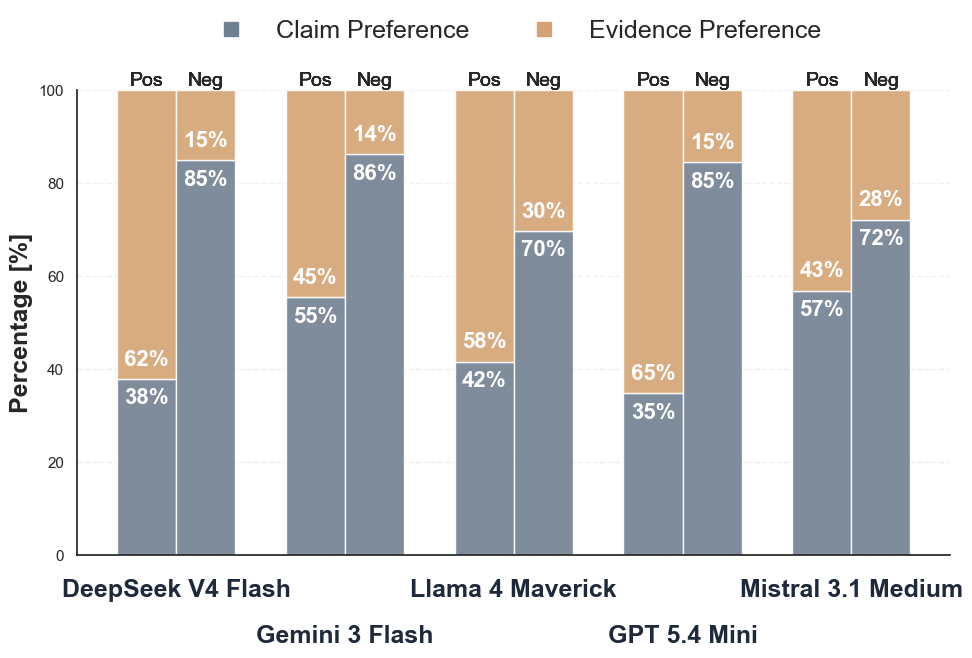

In [850]:
from knowledge_maze.evaluation.metrics.tables.main_tables import MetricsReporter

# Define your config
model_files = {
    "DeepSeek V4 Flash": "results/baseline/deepseek_deepseek-v4-flash.json",
    "Gemini 3 Flash": "results/baseline/google_gemini-3-flash-preview.json",
    "Llama 4 Maverick": "results/baseline/meta-llama_llama-4-maverick.json",
    "GPT 5.4 Mini": "results/baseline/openai_gpt-5.4-mini.json",
    "Mistral 3.1 Medium": "results/baseline/mistralai_mistral-medium-3.1.json",
}

# Run everything
reporter = MetricsReporter(REPO_PATH)
reporter.run_report(model_files)

In [700]:
from knowledge_maze.evaluation.metrics.tables.exhaustive_recall import run_recall_analysis

# 1. Define your configuration
extraction_models = {
    "Deepseek V4 Flash": "results/extract/deepseek_deepseek-v4-flash.json",
    "Google Gemini 3 Flash": "results/extract/google_gemini-3-flash-preview.json",
    "Meta Llama 4 Mavrick": "results/extract/meta-llama_llama-4-maverick.json",
    "GPT 5.4-mini": "results/extract/openai_gpt-5.4-mini.json",
    "Mistral Medium 3.1": "results/extract/mistralai_mistral-medium-3.1.json"
}

# 2. Call the unified function
_ = run_recall_analysis(extraction_models)

Evaluating recall metrics...
  - Evaluated: Deepseek V4 Flash
  - Evaluated: Google Gemini 3 Flash
  - Evaluated: Meta Llama 4 Mavrick
  - Evaluated: GPT 5.4-mini
  - Evaluated: Mistral Medium 3.1

--- Recall Analysis Report ---


,Model,Total,Claim Recall,Evidence Recall,Joint Recall
0,Deepseek V4 Flash,2669,95.2,70.5,68.7
1,Google Gemini 3 Flash,2669,97.3,73.4,71.6
2,Meta Llama 4 Mavrick,2669,87.0,47.4,37.2
3,GPT 5.4-mini,2669,94.8,21.1,17.8
4,Mistral Medium 3.1,2669,88.2,57.7,56.2


In [863]:
import pandas as pd

def analyze_classification_percentages(test_results_baseline):
    """
    Parses baseline test results and outputs a DataFrame summarizing 
    the percentage of 'evidence' vs 'claim' classifications per model.
    """
    records = []
    
    for model_name, questions_dict in test_results_baseline.items():
        total_responses = 0
        evidence_count = 0
        claim_count = 0
        mixed_other_count = 0
        
        for q_id, q_data in questions_dict.items():
            responses = q_data.get('responses', [])
            for r in responses:
                judge = r.get('judge_results', {})
                if not judge:
                    continue  # Skip missing/invalid judge results
                
                classification = judge.get('classification', '').lower().strip()
                total_responses += 1
                
                if classification == 'evidence':
                    evidence_count += 1
                elif classification == 'claim':
                    claim_count += 1
                else:
                    # Captures 'mix', 'mixed', 'both', or any fallback case
                    mixed_other_count += 1
        
        # Calculate percentages safely
        if total_responses > 0:
            evidence_pct = (evidence_count / total_responses) * 100
            claim_pct = (claim_count / total_responses) * 100
            mixed_pct = (mixed_other_count / total_responses) * 100
        else:
            evidence_pct = claim_pct = mixed_pct = 0.0

        records.append({
            'Model': model_name,
            'Total Responses': total_responses,
            'Evidence (%)': round(evidence_pct, 2),
            'Claim (%)': round(claim_pct, 2),
            'Other (%)': round(mixed_pct, 2)
        })
        
    # Convert to DataFrame
    df = pd.DataFrame(records)
    
    # Sort by Evidence percentage descending for better readability
    df = df.sort_values(by='Evidence (%)', ascending=False).reset_index(drop=True)
    return df

# --- Usage ---
df_analysis = analyze_classification_percentages(test_results_baseline)
display(df_analysis)

,Model,Total Responses,Evidence (%),Claim (%),Other (%)
0,Llama 4 Maverick,13327,35.39,62.74,1.86
1,Mistral 3.1 Medium,13328,32.29,65.64,2.08
2,Gemini 3 Flash,13338,20.93,77.45,1.63
3,DeepSeek V4 Flash,13345,18.74,81.03,0.22
4,GPT 5.4 Mini,13339,17.83,81.43,0.73


In [867]:
import pandas as pd

def analyze_context_salience(dataset):
    """
    Analyzes relative order and boundary salience of evidence and claims.
    Salience is defined by how close a position is to the nearest edge (1 or 10).
    """
    total_iterations = 0
    
    # Order Counters
    ev_before_cl = 0
    cl_before_ev = 0
    
    # Salience Counters
    ev_more_salient = 0
    cl_more_salient = 0
    equal_salience = 0

    for q_id, q_data in dataset.items():
        context_list = q_data.get("Context", [])
        for iteration in context_list:
            ev = iteration.get("ev_pos")
            cl = iteration.get("cl_pos")
            
            if ev is None or cl is None:
                continue
                
            total_iterations += 1
            
            # 1. Relative Order
            if ev < cl:
                ev_before_cl += 1
            elif cl < ev:
                cl_before_ev += 1
            # Note: if ev == cl, it won't increment either order counter, 
            # but will naturally fall into equal salience below.
                
            # 2. Salience Logic (Proximity to nearest edge 1 or 10)
            ev_dist = min(ev - 1, 10 - ev)
            cl_dist = min(cl - 1, 10 - cl)
            
            if ev_dist < cl_dist:
                ev_more_salient += 1
            elif cl_dist < ev_dist:
                cl_more_salient += 1
            else:
                equal_salience += 1

    if total_iterations == 0:
        print("No valid iterations found.")
        return None

    report_data = {
        "Metric": [
            "Evidence before Claim",
            "Claim before Evidence",
            "Evidence is more Salient (Closer to an edge)",
            "Claim is more Salient (Closer to an edge)",
            "Equal Salience"
        ],
        "Count": [
            ev_before_cl, 
            cl_before_ev, 
            ev_more_salient, 
            cl_more_salient, 
            equal_salience
        ],
        "Percentage (%)": [
            (ev_before_cl / total_iterations) * 100,
            (cl_before_ev / total_iterations) * 100,
            (ev_more_salient / total_iterations) * 100,
            (cl_more_salient / total_iterations) * 100,
            (equal_salience / total_iterations) * 100
        ]
    }

    df_report = pd.DataFrame(report_data)
    df_report["Percentage (%)"] = df_report["Percentage (%)"].round(2)
    
    print(f"Total Context Iterations Analyzed: {total_iterations}\n")
    return df_report

# --- Usage Example ---
df_salience = analyze_context_salience(load_json(os.path.join(REPO_PATH, "results/preprocessed_data/full_study.json")))
display(df_salience)

Total Context Iterations Analyzed: 13345



,Metric,Count,Percentage (%)
0,Evidence before Claim,6702,50.22
1,Claim before Evidence,6643,49.78
2,Evidence is more Salient (Closer to an edge),5879,44.05
3,Claim is more Salient (Closer to an edge),5933,44.46
4,Equal Salience,1533,11.49


# Ablation Studies Results:

In [846]:
from knowledge_maze.evaluation.metrics.tables.ablation_tables import run_all_ablations
run_all_ablations()

--- CoT Ablation Report ---


,Model,Version,Ack,StableAck,Claim,Mix,Evidence,CondClaim,CondEvid
0,DeepSeek V4,Baseline,7.8,0.5,76.5,14.3,9.3,37.8,62.2
1,,CoT,25.3 (+17.5),7.6 (+7.1),72.2 (-4.3),17.4 (+3.2),10.4 (+1.1),56.6 (+18.8),43.4 (-18.8)
2,Gemini 3,Baseline,22.7,11.0,72.3,17.3,10.4,57.6,42.4
3,,CoT,41.9 (+19.2),26.8 (+15.8),67.5 (-4.8),20.4 (+3.1),12.1 (+1.7),65.8 (+8.2),34.1 (-8.2)
4,Llama 4,Baseline,20.9,6.7,57.3,18.0,24.8,43.6,56.4
5,,CoT,27.8 (+6.9),10.1 (+3.5),51.1 (-6.1),20.7 (+2.7),28.2 (+3.4),51.4 (+7.8),48.6 (-7.8)



--- Hedging Ablation Report ---


,Model,Version,Ack,StableAck,Claim,Mix,Evidence,CondClaim,CondEvid
0,DeepSeek V4,Baseline,8.4,0.8,79.2,13.2,7.6,41.8,58.2
1,,Hedge,14.0 (+5.6),3.0 (+2.2),59.7 (-19.5),21.5 (+8.3),18.8 (+11.1),22.6 (-19.2),77.4 (+19.2)
2,Gemini 3,Baseline,25.6,12.7,73.8,16.9,9.3,58.2,41.8
3,,Hedge,33.5 (+7.9),18.0 (+5.3),59.8 (-14.0),20.5 (+3.6),19.6 (+10.4),43.2 (-15.0),56.8 (+15.0)
4,Llama 4,Baseline,18.9,5.1,59.1,17.1,23.8,43.9,56.1
5,,Hedge,20.8 (+1.9),6.6 (+1.5),50.9 (-8.2),20.6 (+3.5),28.5 (+4.7),39.9 (-4.1),60.1 (+4.1)



--- Scaling Comparison Report ---


,Model,Version,Ack,StableAck,Claim,Mix,Evidence,CondClaim,CondEvid
0,DeepSeek V4,Baseline,8.0,0.6,74.9,13.6,11.4,38.2,61.8
1,,Large,13.9 (+5.9),1.4 (+0.9),68.9 (-6.0),18.7 (+5.1),12.4 (+0.9),38.1 (-0.1),61.9 (+0.1)
2,GPT 5.4,Baseline,5.6,0.7,77.4,12.6,10.0,33.1,66.9
3,,Large,8.3 (+2.7),1.5 (+0.7),70.8 (-6.7),13.5 (+1.0),15.7 (+5.7),57.7 (+24.6),42.3 (-24.6)


# Evidence Volume Analysis:

Loading datasets...
Building scaling dataframe...
Generating scaling plots...


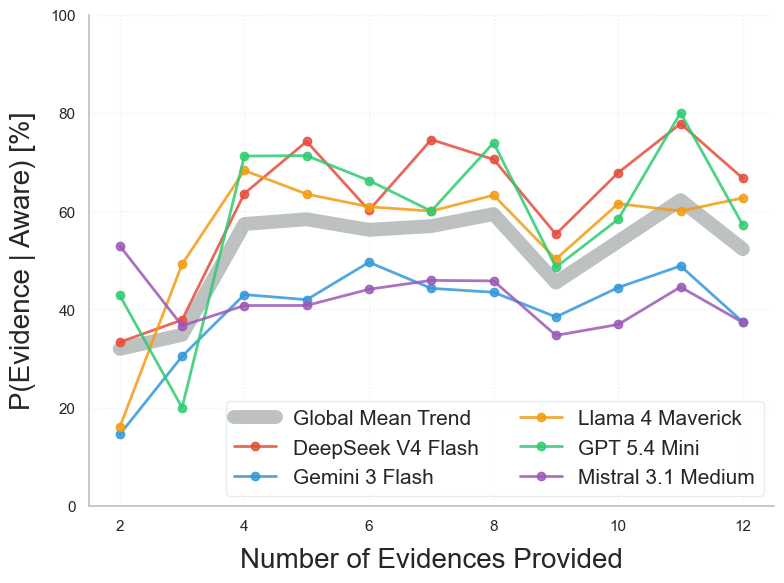

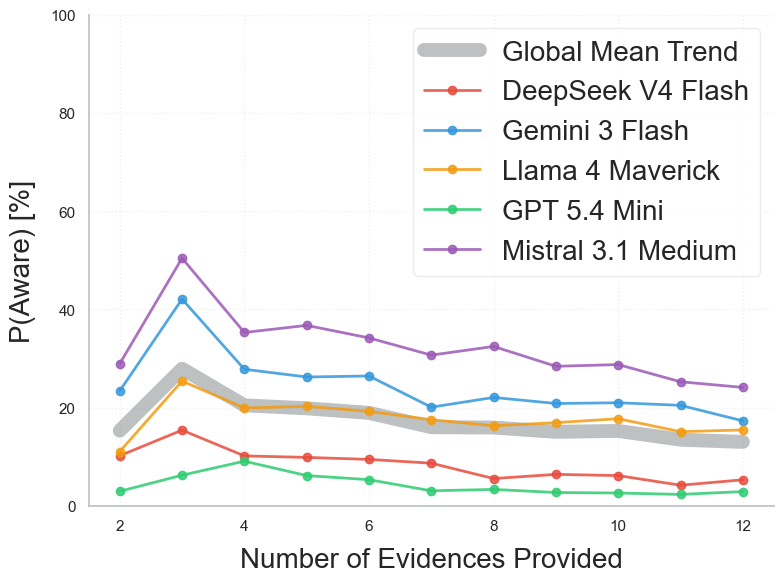

In [870]:
from knowledge_maze.evaluation.metrics.plots.evidence_volume import run_scaling_analysis

run_scaling_analysis()

# Strategy Results Analysis:

Loading evaluation results from: C:\Users\Daniel\Desktop\KnowledgeMaze...
Saved P(Evidence | Awareness) [%] -> strategy_conditioned_preference.pdf


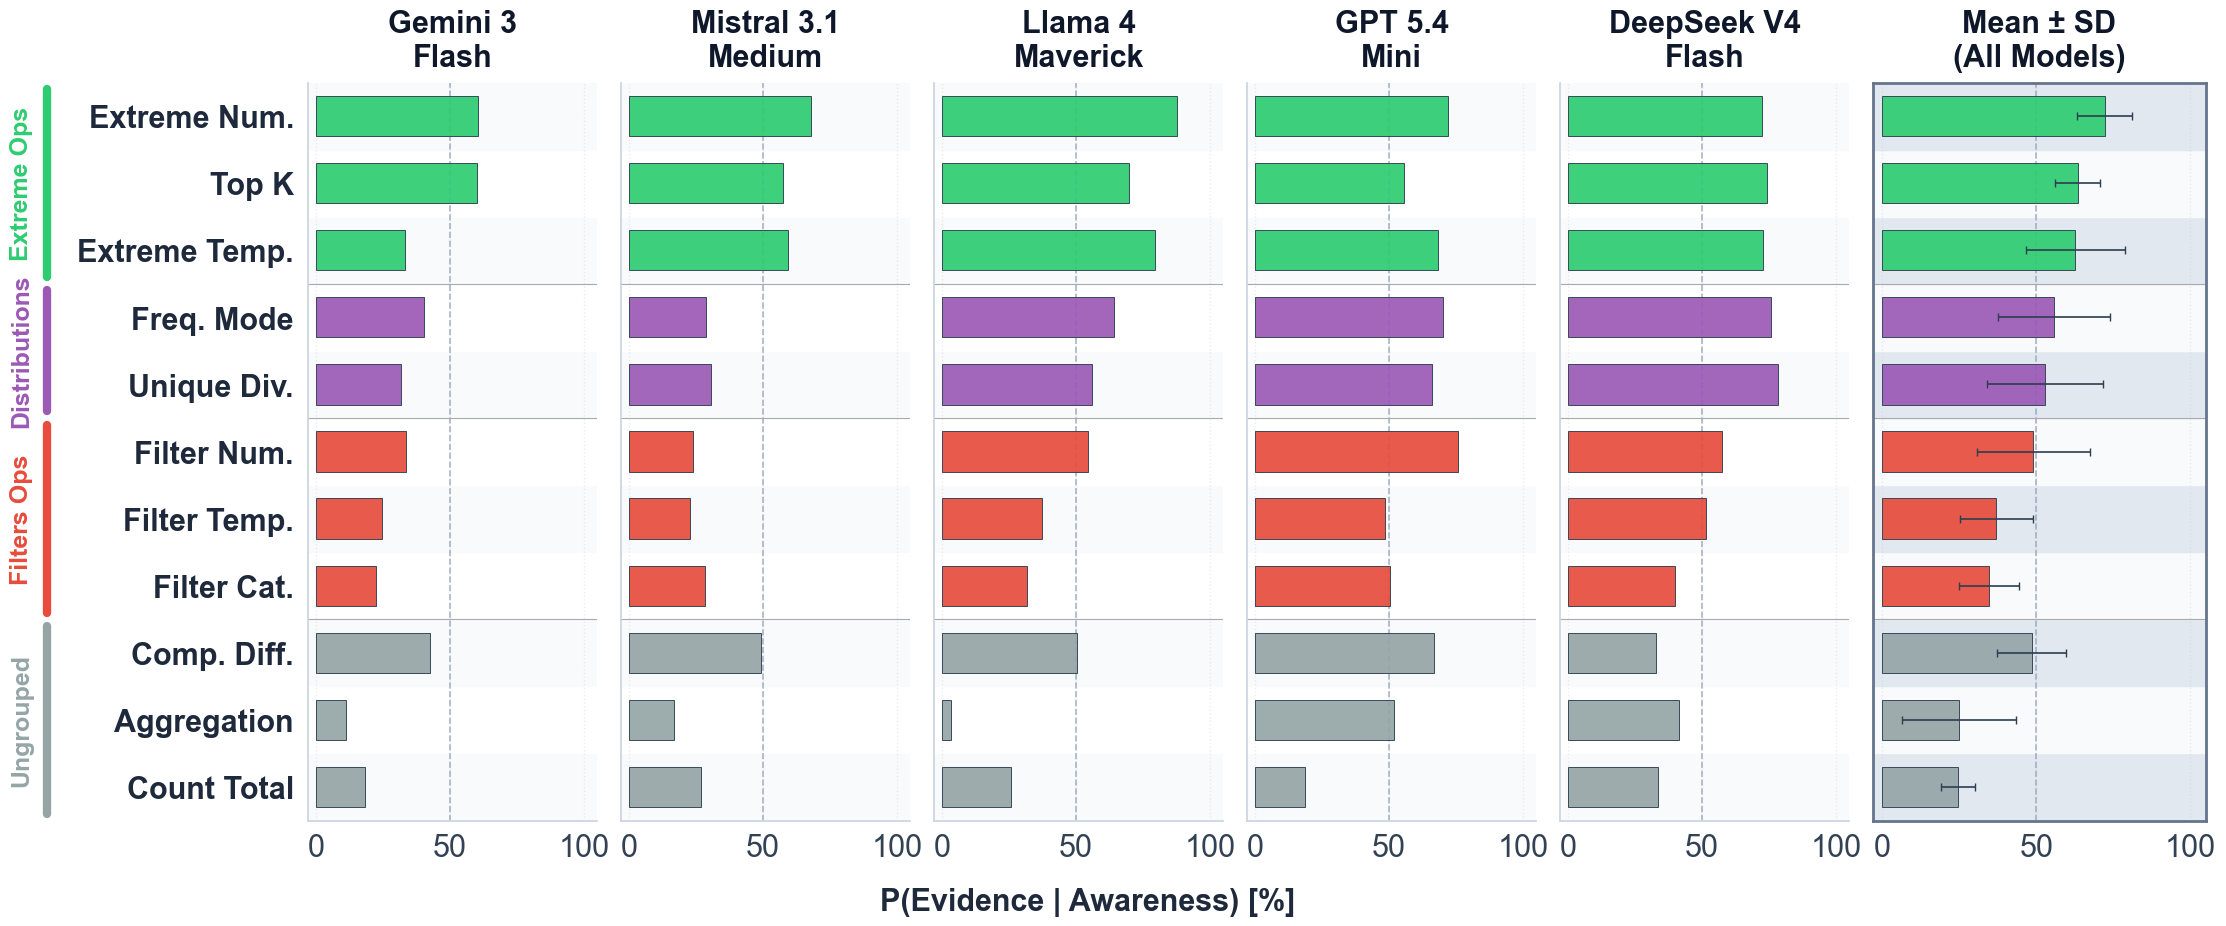

Saved Awareness Rate [%] -> strategy_awareness_rate.pdf


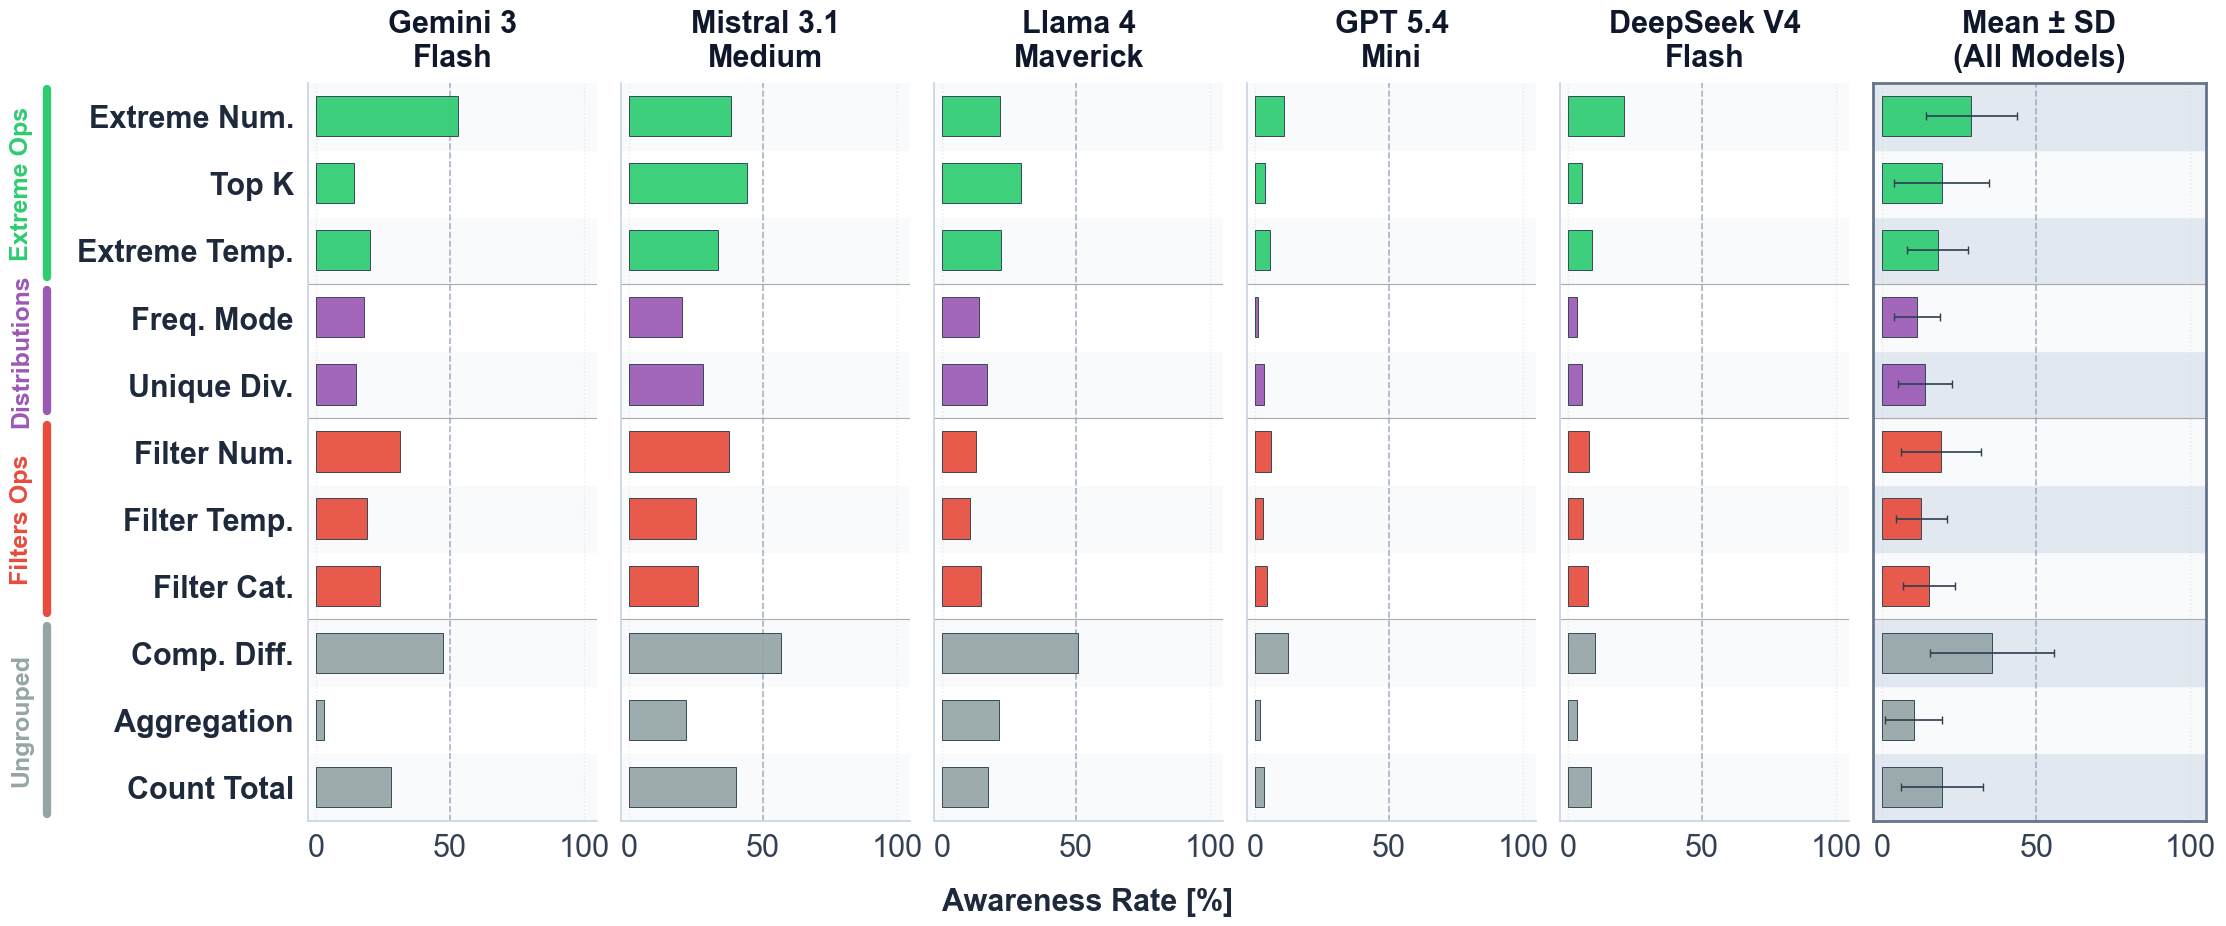

Saved Stacked Preference -> strategy_stable_preference.pdf


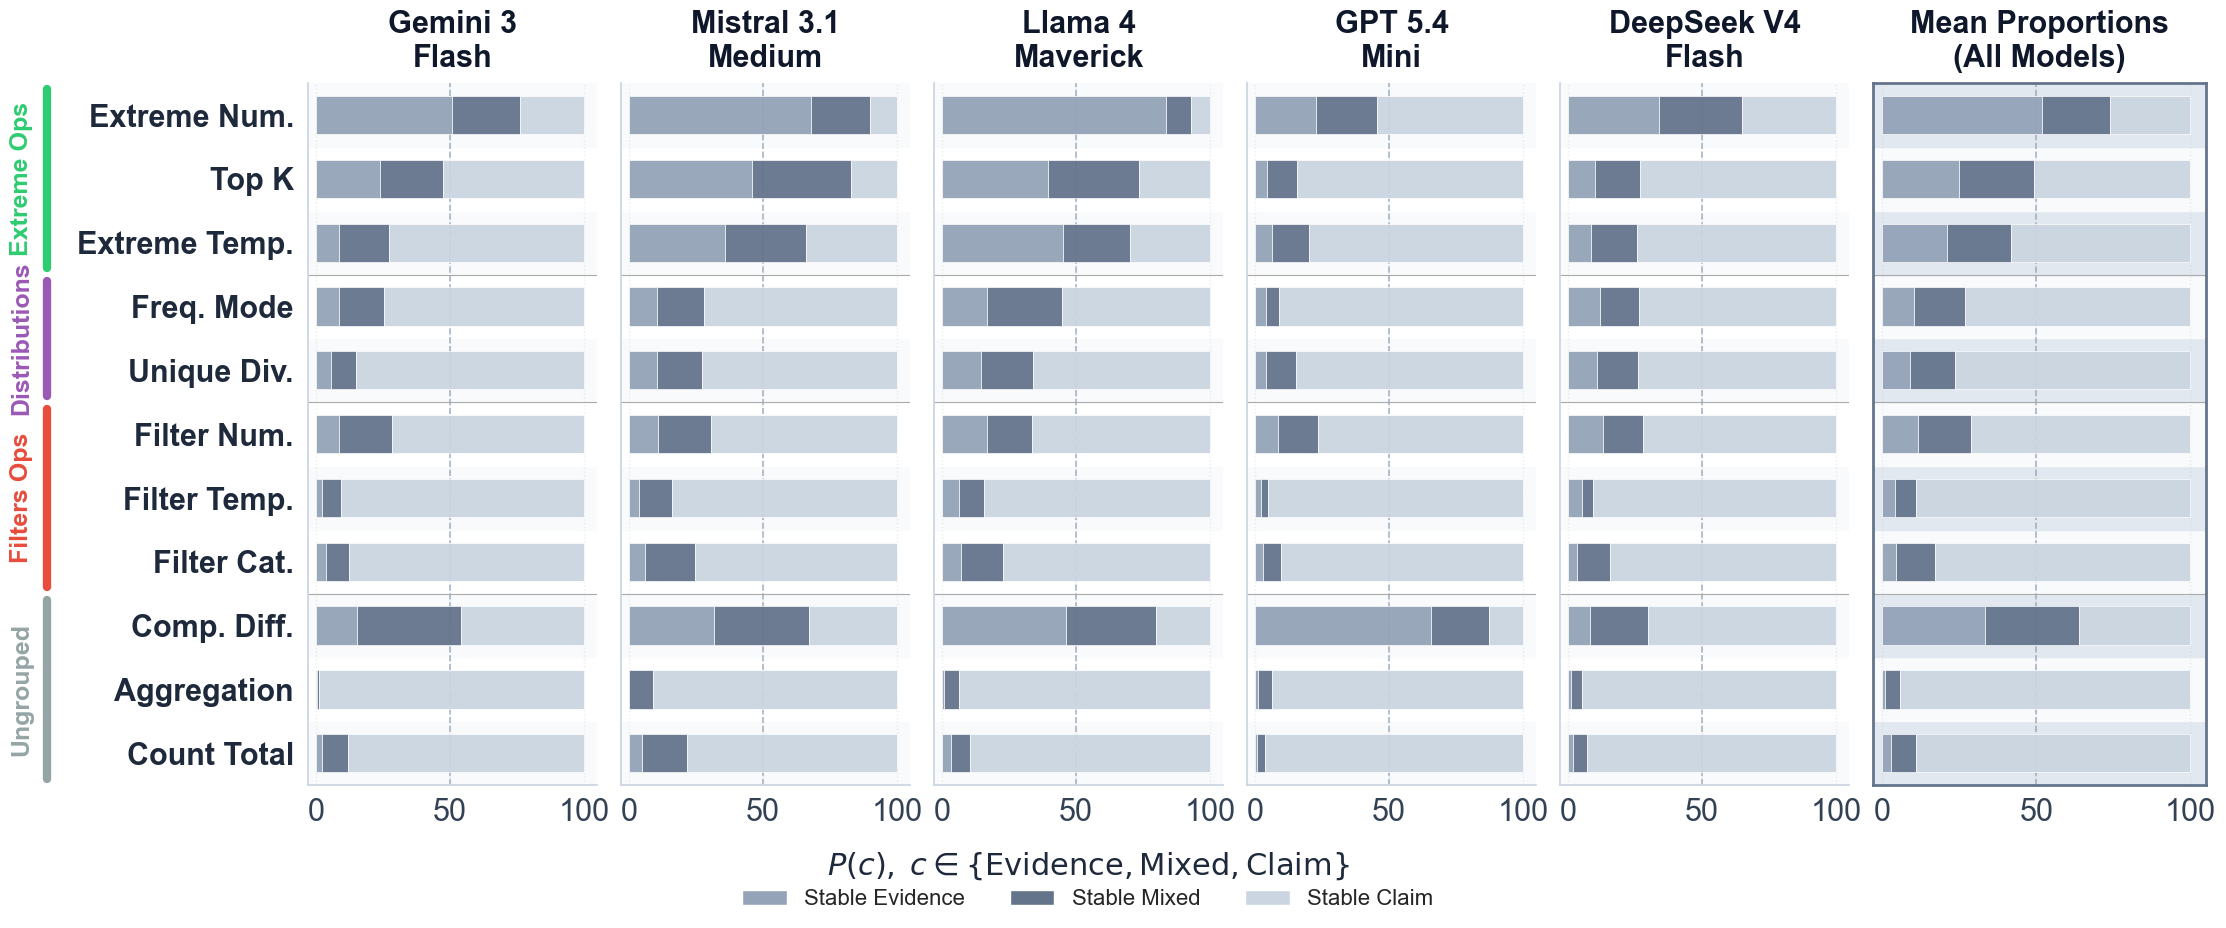

In [860]:
from knowledge_maze.evaluation.metrics.plots.strategy import display_strategy_report

display_strategy_report()